# SVM & the Kernel Trick on `make_moons`

Linear, polynomial and RBF SVMs compared on the same data. All three use the same train/test split
and the same CV folds. Parameters are picked by 5-fold stratified CV on the training set
(scored by balanced accuracy). The test set is only used at the end.

## 1. Setup

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import make_pipeline

import svm_utils as su

warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(su.RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "font.size": 10})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

## 2. Data
600 points, 2 features, `noise=0.25`.

In [2]:
X, y = su.load_moons(n_samples=600, noise=0.25)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("\nFeature summary (original scale):")
print(f"{'':>6}{'mean':>8}{'std':>8}{'min':>8}{'max':>8}")
for j in range(X.shape[1]):
    print(f"{'x'+str(j+1):>6}{X[:, j].mean():>8.2f}{X[:, j].std():>8.2f}"
          f"{X[:, j].min():>8.2f}{X[:, j].max():>8.2f}")

X shape: (600, 2) | y shape: (600,)
Class counts: {0: 300, 1: 300}

Feature summary (original scale):
          mean     std     min     max
    x1    0.51    0.91   -1.50    2.53
    x2    0.27    0.56   -1.17    1.68


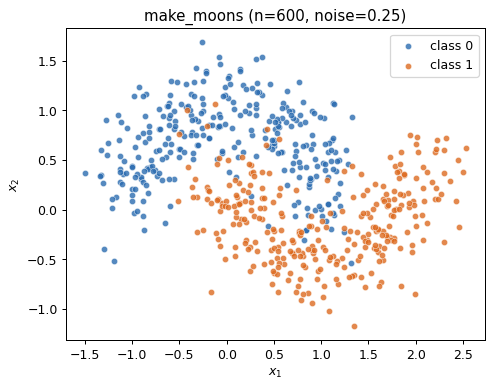

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
su.plot_dataset(X, y, ax=ax, title="make_moons (n=600, noise=0.25)")
ax.legend()
save(fig, "01_dataset")
plt.show()

The two classes are interleaving crescents. Each moon's tip reaches into the other moon's hollow,
so a straight line will always cut off one of the tips. I expect a linear model to top out
somewhere in the mid-80s. The noise also makes the moons overlap in the middle, so even a
perfect curve won't reach 100%.

The classes are balanced (300/300). `x1` has a wider range than `x2`, so I scale the features
before using any distance-based kernel.

## 3. Split and scaling
75/25 stratified split. The scaler is placed **inside a Pipeline**, so in each CV fold it is fitted
only on that fold's training part. The test set never influences the scaling.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=su.RANDOM_STATE)

print("train:", X_train.shape, "class counts", np.bincount(y_train))
print("test: ", X_test.shape, "class counts", np.bincount(y_test))

# Illustration only: the scaler is fitted on the training data alone ...
scaler = StandardScaler().fit(X_train)
print("\nScaler mean (train):", scaler.mean_.round(3), " scale:", scaler.scale_.round(3))
# ... and only *applied* to the test data, so test statistics never leak into training.
print("Scaled test-set mean (not exactly 0, as expected):",
      scaler.transform(X_test).mean(axis=0).round(3))

train: (450, 2) class counts [225 225]
test:  (150, 2) class counts [75 75]

Scaler mean (train): [0.49  0.285]  scale: [0.906 0.559]
Scaled test-set mean (not exactly 0, as expected): [ 0.075 -0.082]


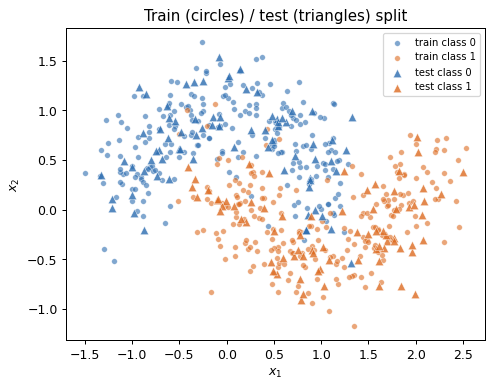

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
su.plot_dataset(X_train, y_train, ax=ax, label_prefix="train ", s=20, alpha=0.6)
su.plot_dataset(X_test, y_test, ax=ax, label_prefix="test ", marker="^", s=45)
ax.set_title("Train (circles) / test (triangles) split")
ax.legend(fontsize=8)
plt.show()

## 4. Linear SVM (baseline)
Grid: `C` from 0.001 to 1000 (log scale).

In [6]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

lin_search = su.grid_search(su.build_pipeline("linear"), {"svc__C": C_GRID}, X_train, y_train)
su.print_cv_table(lin_search, ["svc__C"])
print("\nBest:", lin_search.best_params_, f"CV balanced accuracy = {lin_search.best_score_:.3f}")

       C  train_bal   cv_bal  cv_std  cv_acc   cv_f1
----------------------------------------------------
     0.1      0.861    0.862   0.024   0.862   0.864
  1000.0      0.866    0.862   0.017   0.862   0.865
   100.0      0.866    0.862   0.017   0.862   0.865
    10.0      0.866    0.862   0.017   0.862   0.865
     1.0      0.865    0.858   0.019   0.858   0.861
    0.01      0.849    0.849   0.029   0.849   0.851
   0.001      0.847    0.847   0.019   0.847   0.846

Best: {'svc__C': 0.1} CV balanced accuracy = 0.862


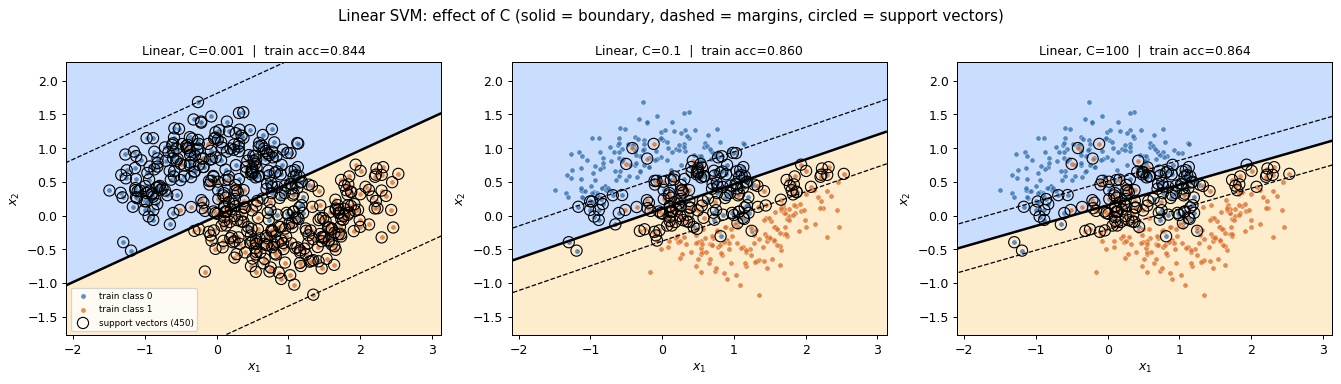

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, C in zip(axes, [0.001, 0.1, 100]):
    m = su.build_pipeline("linear", C=C).fit(X_train, y_train)
    su.plot_decision_boundary(m, X_train, y_train, ax=ax,
        title=f"Linear, C={C}  |  train acc={m.score(X_train, y_train):.3f}")
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Linear SVM: effect of C (solid = boundary, dashed = margins, circled = support vectors)")
plt.tight_layout(); save(fig, "02_linear_C"); plt.show()

The line barely moves as `C` changes. Only the margin width changes: at `C=0.001` every training
point is a support vector, and by `C=0.1` there are 170. Accuracy stays around 86%, which is the
best a line can do here.

In [8]:
results = {}
best_lin = lin_search.best_estimator_
results["Linear"] = {"best_params": lin_search.best_params_,
                     "cv_score": lin_search.best_score_,
                     "metrics": su.evaluate(best_lin, X_test, y_test),
                     "model": best_lin}
print(results["Linear"]["metrics"])

{'accuracy': 0.86, 'balanced_accuracy': 0.86, 'f1': 0.8627450980392157, 'confusion_matrix': array([[63, 12],
       [ 9, 66]]), 'n_support_vectors': 170}


## 5. Polynomial kernel
$K(x,z) = (\gamma x^\top z + r)^d$. I set `coef0=1`. With `coef0=0`, a degree-2 kernel would
only contain squared terms and no linear ones.
Grid: `degree` ∈ {2, 3, 4, 5} × `C` ∈ {0.001 … 1000}.

In [9]:
poly_grid = {"svc__degree": [2, 3, 4, 5], "svc__C": C_GRID}
poly_search = su.grid_search(su.build_pipeline("poly", coef0=1, gamma="scale"),
                             poly_grid, X_train, y_train)
su.print_cv_table(poly_search, ["svc__degree", "svc__C"], top=10)
print("\nBest:", poly_search.best_params_, f"CV balanced accuracy = {poly_search.best_score_:.3f}")

  degree       C  train_bal   cv_bal  cv_std  cv_acc   cv_f1
------------------------------------------------------------
       5  1000.0      0.948    0.936   0.015   0.936   0.935
       5   100.0      0.949    0.936   0.013   0.936   0.934
       5    10.0      0.947    0.933   0.014   0.933   0.932
       4   100.0      0.949    0.933   0.010   0.933   0.932
       4  1000.0      0.948    0.933   0.010   0.933   0.932
       5     1.0      0.942    0.929   0.011   0.929   0.927
       3    10.0      0.940    0.929   0.018   0.929   0.928
       4    10.0      0.946    0.927   0.011   0.927   0.925
       3  1000.0      0.940    0.922   0.019   0.922   0.922
       3   100.0      0.942    0.920   0.020   0.920   0.920

Best: {'svc__C': 100, 'svc__degree': 5} CV balanced accuracy = 0.936


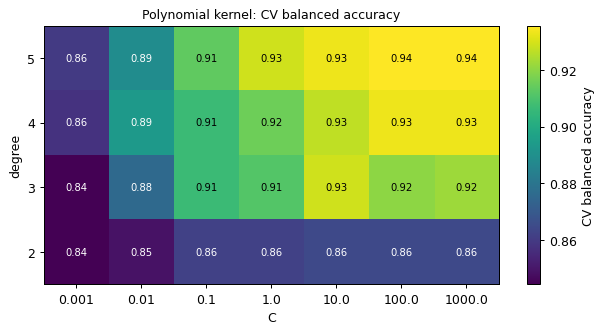

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.8))
su.plot_cv_heatmap(poly_search, "svc__degree", "svc__C", ax=ax,
                   title="Polynomial kernel: CV balanced accuracy")
plt.tight_layout(); save(fig, "03_poly_heatmap"); plt.show()

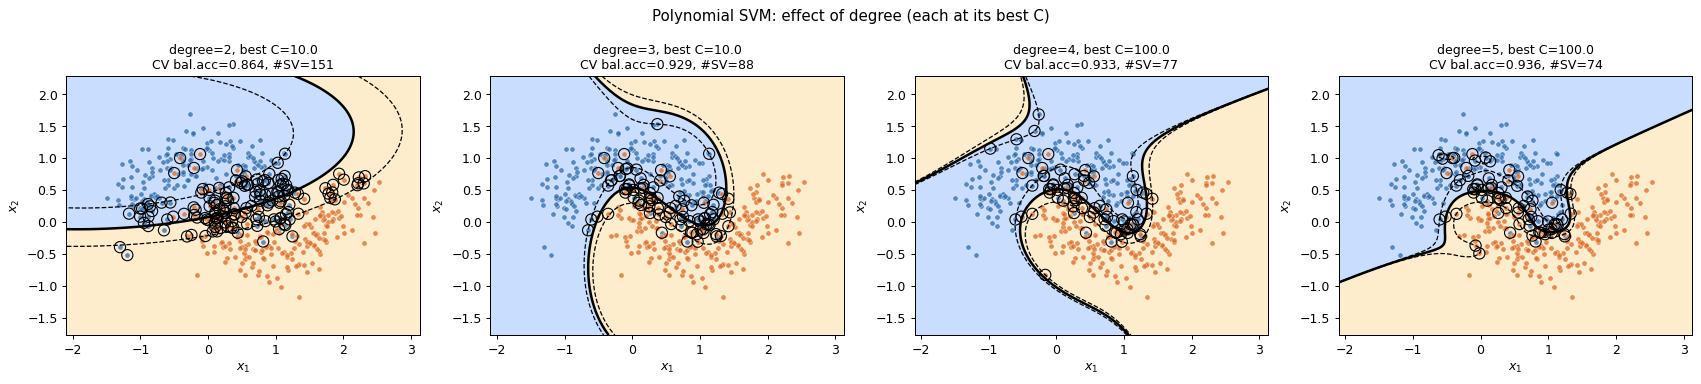

In [11]:
# Best C for each degree, then plot the boundary for each degree
res = poly_search.cv_results_
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, d in zip(axes, [2, 3, 4, 5]):
    mask = np.array(res["param_svc__degree"]) == d
    i = np.flatnonzero(mask)[np.argmax(res["mean_test_balanced_accuracy"][mask])]
    C = res["param_svc__C"][i]
    m = su.build_pipeline("poly", degree=d, C=C, coef0=1, gamma="scale").fit(X_train, y_train)
    su.plot_decision_boundary(m, X_train, y_train, ax=ax,
        title=f"degree={d}, best C={C}\nCV bal.acc={res['mean_test_balanced_accuracy'][i]:.3f}, "
              f"#SV={m.named_steps['svc'].n_support_.sum()}")
fig.suptitle("Polynomial SVM: effect of degree (each at its best C)")
plt.tight_layout(); save(fig, "04_poly_degree"); plt.show()

* Degree 2 bends only once (an ellipse) and scores about the same as the linear model.
* Degree 3 is the first that gives the S-shape between the moons, and the CV score jumps to about 0.93.
* Degrees 4–5 are only slightly better and need `C ≥ 100`. Outside the data the boundary goes strange.
  Look at the extra orange region in the top-left corner for degree 4. Polynomial terms grow quickly
  away from the origin.

In [12]:
best_poly = poly_search.best_estimator_
results["Polynomial"] = {"best_params": poly_search.best_params_,
                         "cv_score": poly_search.best_score_,
                         "metrics": su.evaluate(best_poly, X_test, y_test),
                         "model": best_poly}
print(results["Polynomial"]["metrics"])

{'accuracy': 0.9466666666666667, 'balanced_accuracy': 0.9466666666666667, 'f1': 0.9466666666666667, 'confusion_matrix': array([[71,  4],
       [ 4, 71]]), 'n_support_vectors': 74}


## 6. RBF kernel
$K(x,z) = \exp(-\gamma\|x-z\|^2)$. `gamma` controls how far each support vector's influence reaches.
Grid: `gamma` ∈ {0.01 … 50} × `C` ∈ {0.001 … 1000}.

In [13]:
GAMMA_GRID = [0.01, 0.1, 0.5, 1, 2, 5, 10, 50]
rbf_grid = {"svc__gamma": GAMMA_GRID, "svc__C": C_GRID}
rbf_search = su.grid_search(su.build_pipeline("rbf"), rbf_grid, X_train, y_train)
su.print_cv_table(rbf_search, ["svc__gamma", "svc__C"], top=10)
print("\nBest:", rbf_search.best_params_, f"CV balanced accuracy = {rbf_search.best_score_:.3f}")

   gamma       C  train_bal   cv_bal  cv_std  cv_acc   cv_f1
------------------------------------------------------------
     2.0    10.0      0.951    0.942   0.011   0.942   0.942
     1.0   100.0      0.951    0.938   0.011   0.938   0.937
     1.0    10.0      0.949    0.938   0.011   0.938   0.936
     0.5   100.0      0.952    0.938   0.011   0.938   0.937
     2.0     1.0      0.947    0.936   0.025   0.936   0.935
     1.0     1.0      0.938    0.933   0.019   0.933   0.933
     1.0  1000.0      0.952    0.933   0.014   0.933   0.933
     0.5  1000.0      0.950    0.933   0.012   0.933   0.932
     5.0     1.0      0.948    0.931   0.019   0.931   0.931
     2.0   100.0      0.952    0.931   0.013   0.931   0.931

Best: {'svc__C': 10, 'svc__gamma': 2} CV balanced accuracy = 0.942


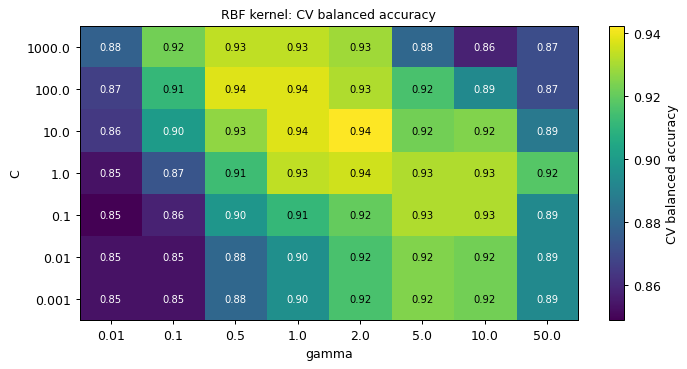

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
su.plot_cv_heatmap(rbf_search, "svc__C", "svc__gamma", ax=ax,
                   title="RBF kernel: CV balanced accuracy")
plt.tight_layout(); save(fig, "05_rbf_heatmap"); plt.show()

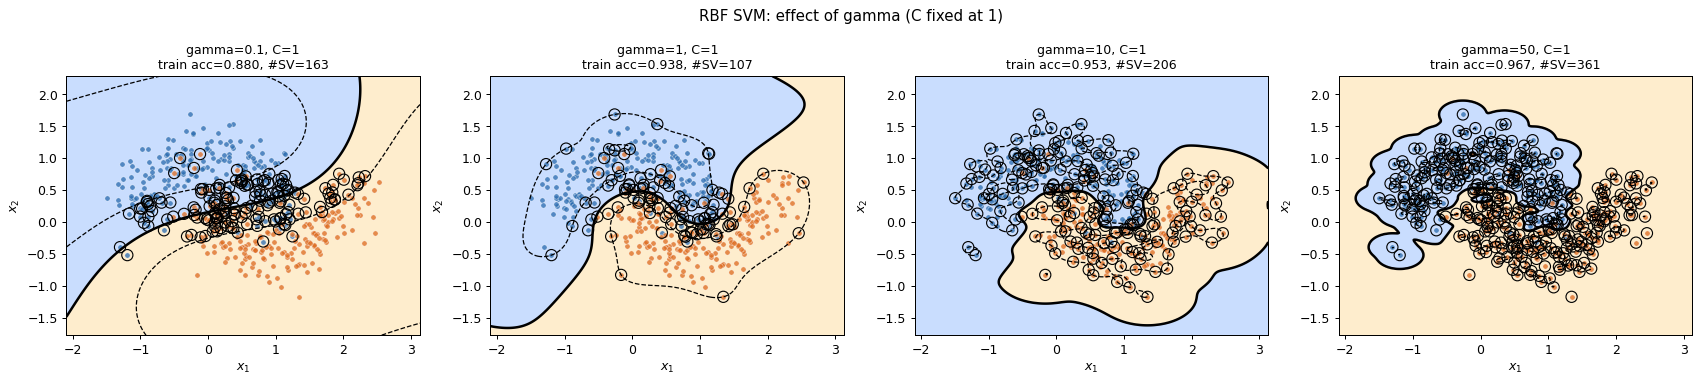

In [15]:
# Effect of gamma at fixed C = 1
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, g in zip(axes, [0.1, 1, 10, 50]):
    m = su.build_pipeline("rbf", gamma=g, C=1).fit(X_train, y_train)
    su.plot_decision_boundary(m, X_train, y_train, ax=ax,
        title=f"gamma={g}, C=1\ntrain acc={m.score(X_train, y_train):.3f}, "
              f"#SV={m.named_steps['svc'].n_support_.sum()}")
fig.suptitle("RBF SVM: effect of gamma (C fixed at 1)")
plt.tight_layout(); save(fig, "06_rbf_gamma"); plt.show()

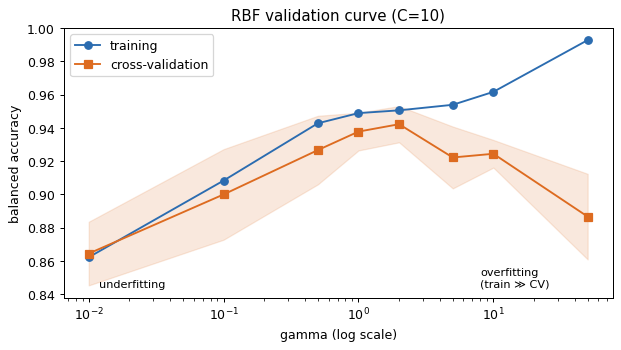

In [16]:
# Validation curve for gamma: training vs. cross-validation score at the best C
best_C = rbf_search.best_params_["svc__C"]
res = rbf_search.cv_results_
mask = np.array(res["param_svc__C"]) == best_C
g = np.array(res["param_svc__gamma"][mask], dtype=float)
order = np.argsort(g)
tr = res["mean_train_balanced_accuracy"][mask][order]
cv = res["mean_test_balanced_accuracy"][mask][order]
cv_std = res["std_test_balanced_accuracy"][mask][order]

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(g[order], tr, "o-", color="#2b6cb0", label="training")
ax.semilogx(g[order], cv, "s-", color="#dd6b20", label="cross-validation")
ax.fill_between(g[order], cv - cv_std, cv + cv_std, color="#dd6b20", alpha=0.15)
ax.set_xlabel("gamma (log scale)"); ax.set_ylabel("balanced accuracy")
ax.set_title(f"RBF validation curve (C={best_C})")
ax.annotate("underfitting", xy=(g[order][0], cv[0]), xytext=(0.012, cv.min() - 0.02), fontsize=9)
ax.annotate("overfitting\n(train ≫ CV)", xy=(g[order][-1], cv[-1]), xytext=(8, cv.min() - 0.02), fontsize=9)
ax.legend(); plt.tight_layout(); save(fig, "07_rbf_validation_curve"); plt.show()

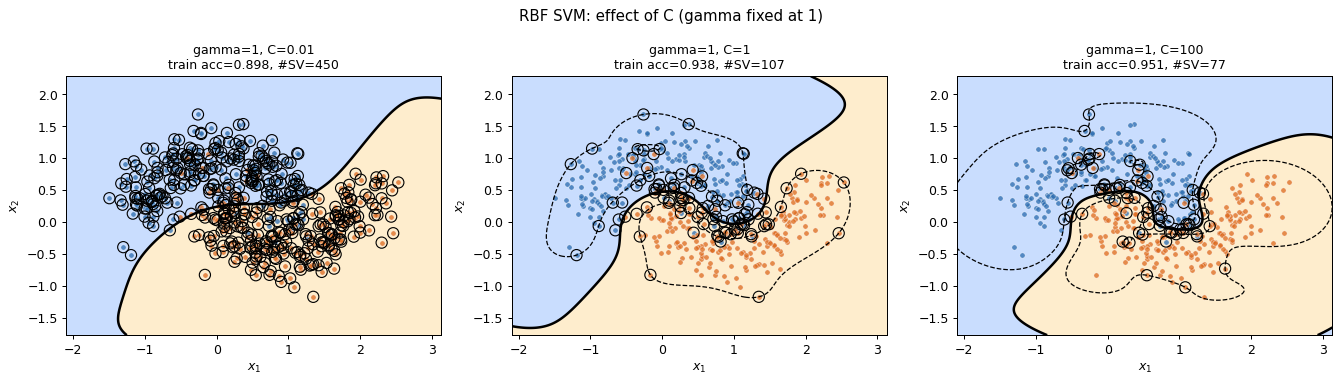

In [17]:
# Effect of C at fixed gamma = 1
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, C in zip(axes, [0.01, 1, 100]):
    m = su.build_pipeline("rbf", gamma=1, C=C).fit(X_train, y_train)
    su.plot_decision_boundary(m, X_train, y_train, ax=ax,
        title=f"gamma=1, C={C}\ntrain acc={m.score(X_train, y_train):.3f}, "
              f"#SV={m.named_steps['svc'].n_support_.sum()}")
fig.suptitle("RBF SVM: effect of C (gamma fixed at 1)")
plt.tight_layout(); plt.show()

* `gamma=0.1`: almost a straight line, so it underfits.
* `gamma` around 1–2: follows the moons well.
* `gamma=10–50`: small islands form around individual points, and nearly every point becomes a
  support vector (361 at γ=50). On the validation curve, training accuracy keeps going up while CV
  accuracy drops after γ=2. That is overfitting.
* The good region in the heat-map runs diagonally: a smaller γ can be compensated by a larger `C`.
  So γ and `C` have to be tuned together.

In [18]:
best_rbf = rbf_search.best_estimator_
results["RBF"] = {"best_params": rbf_search.best_params_,
                  "cv_score": rbf_search.best_score_,
                  "metrics": su.evaluate(best_rbf, X_test, y_test),
                  "model": best_rbf}
print(results["RBF"]["metrics"])

{'accuracy': 0.94, 'balanced_accuracy': 0.94, 'f1': 0.9395973154362416, 'confusion_matrix': array([[71,  4],
       [ 5, 70]]), 'n_support_vectors': 97}


## 7. Comparison

In [19]:
su.print_summary(results)

model       best parameters                        CV bal.acc  test acc test bal.acc  test F1   #SV
---------------------------------------------------------------------------------------------------
Linear      C=0.1                                       0.862     0.860        0.860    0.863   170
Polynomial  C=100, degree=5                             0.936     0.947        0.947    0.947    74
RBF         C=10, gamma=2                               0.942     0.940        0.940    0.940    97


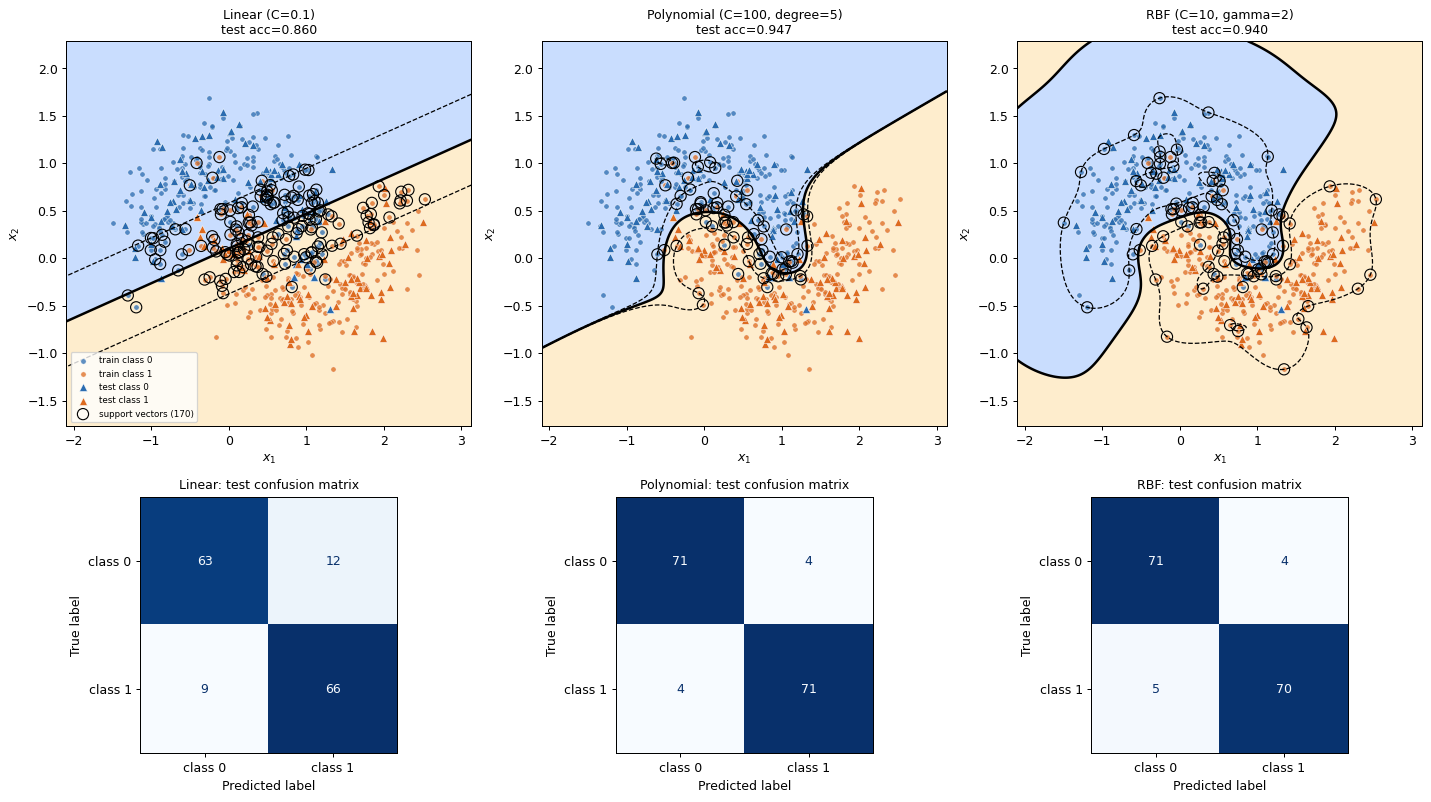

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), gridspec_kw={"height_ratios": [3, 2]})
for j, (name, r) in enumerate(results.items()):
    p = ", ".join(f"{k.replace('svc__', '')}={v}" for k, v in r["best_params"].items())
    su.plot_decision_boundary(r["model"], X_train, y_train, X_test, y_test, ax=axes[0, j],
        title=f"{name} ({p})\ntest acc={r['metrics']['accuracy']:.3f}")
    su.plot_confusion(r["metrics"]["confusion_matrix"], ax=axes[1, j], title=f"{name}: test confusion matrix")
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); save(fig, "08_comparison"); plt.show()

In [21]:
# Fit time and prediction cost of each best model
for name, r in results.items():
    t0 = time.perf_counter(); r["model"].fit(X_train, y_train); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); r["model"].predict(X_test); pred_t = time.perf_counter() - t0
    print(f"{name:<11} fit {fit_t*1e3:6.1f} ms | predict {pred_t*1e3:5.2f} ms | "
          f"support vectors {r['model'].named_steps['svc'].n_support_.sum()}")

Linear      fit    2.6 ms | predict  1.14 ms | support vectors 170
Polynomial  fit   33.0 ms | predict  0.64 ms | support vectors 74
RBF         fit    2.9 ms | predict  0.68 ms | support vectors 97


### Model choice: RBF, `gamma=2`, `C=10`

* It has the best CV score (0.942). I chose the model by CV, not by test score.
* The polynomial model scores higher on the test set (0.947 vs 0.940), but that is **1 point out of
  150**, which is smaller than the CV standard deviation (~0.01–0.015). I'd call it a tie.
* Many (γ, C) pairs near the best one score ≥ 0.93, so RBF isn't sensitive to the exact values.
  The polynomial model only competes at degree 5 with `C=100`.
* RBF fits about 10× faster than the degree-5 polynomial and doesn't create odd regions away from the data.

The remaining 8–9 errors are in the noisy overlap in the middle. I don't think any smooth boundary
would get those right.

## 8. Kernel trick

### 8.1 Lifting the data
`make_circles` can't be separated by a line in 2-D. After adding a third feature $x_1^2+x_2^2$
(the squared distance from the centre), a flat plane separates the two classes.

Linear SVM on original 2-D circles : train acc = 0.583
Linear SVM on lifted   3-D features: train acc = 1.000


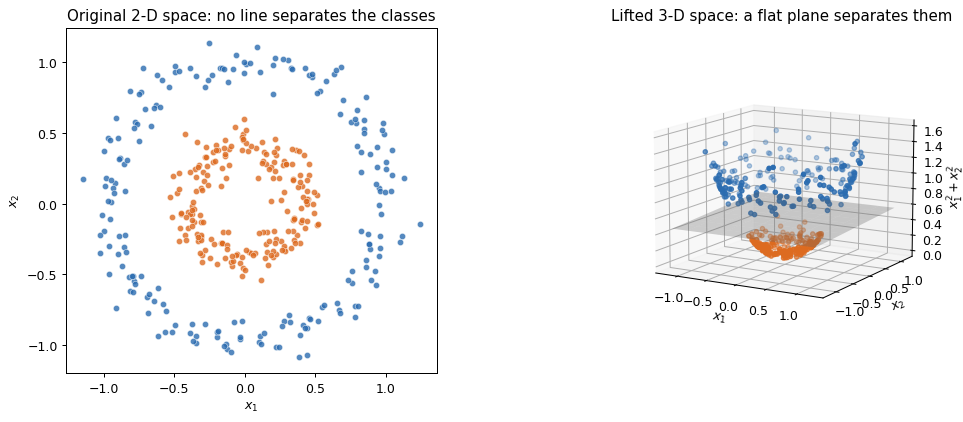

In [22]:
Xc, yc = make_circles(n_samples=400, factor=0.4, noise=0.08, random_state=su.RANDOM_STATE)
Zc = np.c_[Xc, (Xc ** 2).sum(axis=1)]            # explicit map  phi(x) = (x1, x2, x1^2 + x2^2)

lin_2d = SVC(kernel="linear", C=1).fit(Xc, yc)
lin_3d = SVC(kernel="linear", C=1).fit(Zc, yc)
print(f"Linear SVM on original 2-D circles : train acc = {lin_2d.score(Xc, yc):.3f}")
print(f"Linear SVM on lifted   3-D features: train acc = {lin_3d.score(Zc, yc):.3f}")

fig = plt.figure(figsize=(13, 4.8))
ax1 = fig.add_subplot(1, 2, 1)
su.plot_dataset(Xc, yc, ax=ax1, title="Original 2-D space: no line separates the classes")
ax1.set_aspect("equal")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
for cls in (0, 1):
    ax2.scatter(*Zc[yc == cls].T, c=su.CLASS_COLORS[cls], s=12, label=f"class {cls}")
# Separating plane  w.z + b = 0   ->   z3 = -(w1 z1 + w2 z2 + b) / w3
w, b = lin_3d.coef_[0], lin_3d.intercept_[0]
gx, gy = np.meshgrid(np.linspace(-1.2, 1.2, 10), np.linspace(-1.2, 1.2, 10))
ax2.plot_surface(gx, gy, -(w[0] * gx + w[1] * gy + b) / w[2], alpha=0.3, color="grey")
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.set_zlabel("$x_1^2+x_2^2$")
ax2.set_title("Lifted 3-D space: a flat plane separates them")
ax2.view_init(elev=12, azim=-60)
ax2.set_box_aspect(None, zoom=0.85)
plt.tight_layout(); save(fig, "09_kernel_lift"); plt.show()

That plane maps back to a circle in 2-D. A linear model in the new space gives a curved boundary
in the original space.

### 8.2 Same result without building the features
The SVM only uses dot products between points. For 2-D inputs, $(x^\top z + 1)^2$ equals the
dot product of these 6-D vectors:
$\phi(x) = (1, \sqrt2 x_1, \sqrt2 x_2, x_1^2, x_2^2, \sqrt2 x_1x_2)$.
Below, I check that the two are equal. I also train a linear SVM on $\phi(X)$ and a poly-kernel SVM
on $X$. They should give the same model.

In [23]:
def phi_poly2(X):
    # Explicit feature map whose dot product equals (x.z + 1)^2 for 2-D inputs
    x1, x2 = X[:, 0], X[:, 1]
    s = np.sqrt(2)
    return np.c_[np.ones_like(x1), s * x1, s * x2, x1 ** 2, x2 ** 2, s * x1 * x2]

rng = np.random.default_rng(0)
A, B = rng.normal(size=(5, 2)), rng.normal(size=(5, 2))
K_kernel = (A @ B.T + 1) ** 2                 # kernel: 2-D dot product, then square
K_explicit = phi_poly2(A) @ phi_poly2(B).T    # map to 6-D, then dot product
print("Max |K_kernel - K_explicit| =", np.abs(K_kernel - K_explicit).max())

# Same SVM, two routes (on the scaled moons training data)
sc = StandardScaler().fit(X_train)
Xs_tr, Xs_te = sc.transform(X_train), sc.transform(X_test)

svm_explicit = SVC(kernel="linear", C=1).fit(phi_poly2(Xs_tr), y_train)
svm_kernel = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=1).fit(Xs_tr, y_train)

d_exp = svm_explicit.decision_function(phi_poly2(Xs_te))
d_ker = svm_kernel.decision_function(Xs_te)
print("Max difference in decision function on test set:", np.abs(d_exp - d_ker).max().round(6))
print("Predictions identical:", np.array_equal(d_exp > 0, d_ker > 0))

Max |K_kernel - K_explicit| = 1.7763568394002505e-15
Max difference in decision function on test set: 0.0
Predictions identical: True


They give the same decision values, but the kernel version never builds the 6-D vectors.

### 8.3 RBF
The RBF kernel's feature space has infinitely many dimensions (its Taylor expansion contains
every degree), so it can't be built explicitly. Computing $K$ still only takes a distance and an exponential.
The plot shows why a large γ overfits: the similarity drops to zero almost immediately.

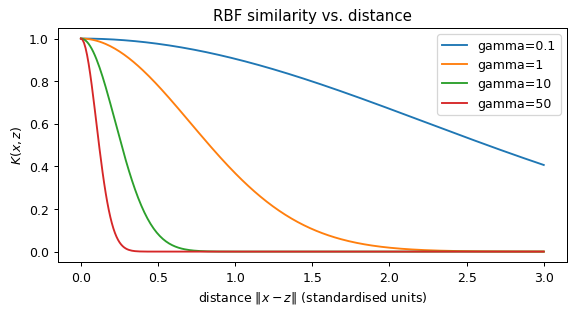

In [24]:
d = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for gval in [0.1, 1, 10, 50]:
    ax.plot(d, np.exp(-gval * d ** 2), label=f"gamma={gval}")
ax.set_xlabel("distance $\\|x - z\\|$ (standardised units)"); ax.set_ylabel("$K(x,z)$")
ax.set_title("RBF similarity vs. distance"); ax.legend()
plt.tight_layout(); save(fig, "10_rbf_similarity"); plt.show()

### 8.4 Cost
Number of features an explicit polynomial map would need, compared with the kernel's cost:

In [25]:
from math import comb
print(f"{'d (inputs)':>11}{'p (degree)':>11}{'explicit features':>20}{'kernel cost ~ d':>17}")
for dd in [2, 10, 100, 1000]:
    for p in [2, 3, 5]:
        print(f"{dd:>11}{p:>11}{comb(dd + p, p):>20,}{dd:>17}")

 d (inputs) p (degree)   explicit features  kernel cost ~ d
          2          2                   6                2
          2          3                  10                2
          2          5                  21                2
         10          2                  66               10
         10          3                 286               10
         10          5               3,003               10
        100          2               5,151              100
        100          3             176,851              100
        100          5          96,560,646              100
       1000          2             501,501             1000
       1000          3         167,668,501             1000
       1000          5   8,459,043,543,951             1000


The flip side is that a kernel SVM's cost grows with the number of **samples**, because it works
with the n×n kernel matrix. libsvm doesn't store the whole matrix (the "full Gram" column shows what
that would need). It caches part of it and recomputes the rest. In this run, fit time grows far
faster than n. Nyström features with a linear SVM grow roughly linearly, catch up with the exact
SVM at around 16k points and give the same accuracy.

In [26]:
print(f"{'n':>7}{'full Gram (MB)':>18}{'SVC rbf fit (s)':>17}{'Nystroem+LinearSVC (s)':>25}"
      f"{'acc SVC':>9}{'acc Nys':>9}")
for n in [1000, 2000, 4000, 8000, 16000]:
    Xn, yn = su.load_moons(n_samples=n + 2000, noise=0.25, random_state=1)
    Xa, ya, Xb, yb = Xn[:n], yn[:n], Xn[n:], yn[n:]
    t0 = time.perf_counter()
    exact = su.build_pipeline("rbf", gamma=1, C=1).fit(Xa, ya)
    t_exact = time.perf_counter() - t0
    t0 = time.perf_counter()
    approx = make_pipeline(StandardScaler(),
                           Nystroem(kernel="rbf", gamma=1, n_components=200, random_state=0),
                           LinearSVC(C=1)).fit(Xa, ya)
    t_approx = time.perf_counter() - t0
    print(f"{n:>7}{n * n * 8 / 1e6:>18.1f}{t_exact:>17.3f}{t_approx:>25.3f}"
          f"{exact.score(Xb, yb):>9.3f}{approx.score(Xb, yb):>9.3f}")

      n    full Gram (MB)  SVC rbf fit (s)   Nystroem+LinearSVC (s)  acc SVC  acc Nys
   1000               8.0            0.005                    0.050    0.948    0.946
   2000              32.0            0.028                    0.098    0.950    0.950
   4000             128.0            0.110                    0.163    0.940    0.941
   8000             512.0            0.258                    0.399    0.938    0.939
  16000            2048.0            0.959                    0.791    0.939    0.941


Other limits: a kernel has to be positive semi-definite to correspond to a real feature space.
You also lose the interpretable weight vector. And the kernel's results depend heavily on
γ / degree / C, as the earlier sections showed.

## 9. Summary
* Linear SVM: ~86%. A line can't follow the moons.
* Polynomial (degree 5) and RBF: ~94%. They reach the noise floor of the overlapping region.
* Chosen model: **RBF (γ=2, C=10)**. It has the best CV score, is robust to its parameters, and
  trains fast.
* Kernel trick: shown numerically. A poly-kernel SVM is identical to a linear SVM on the explicit
  features. The catch is that cost scales with the number of samples, not with the number of features.